### Lab Assignment 1 – Agglomerative Clustering of Credit Card Customer Data

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('CC_Customer_Dataset.csv')

df.head()

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB


In [11]:
from sklearn.preprocessing import StandardScaler

X = df.drop(columns=['Sl_No', 'Customer Key'])

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled.shape

(660, 5)

**Answer:** `Sl_No` and `Customer Key` are identifiers, so the five remaining variables were used and standardized (otherwise `Avg_Credit_Limit` would dominate the Euclidean distance). Ward linkage was used, as in Lab 1.

### Dendrogram and Number of Clusters

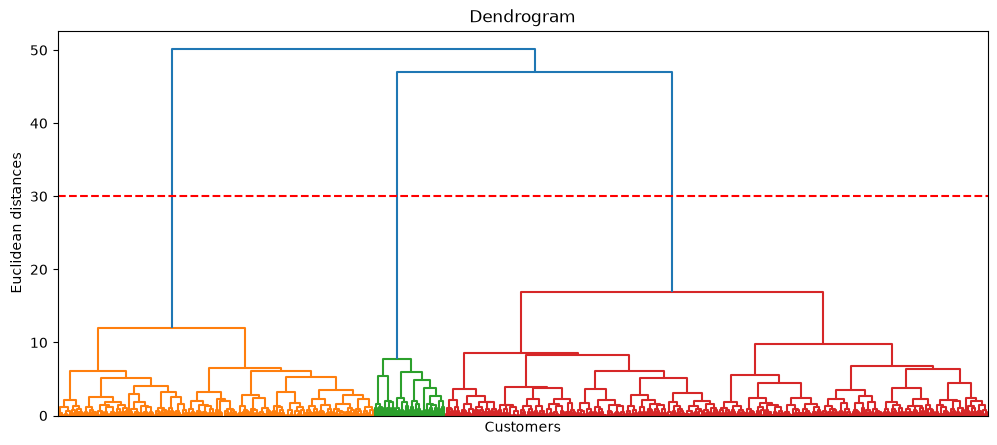

In [12]:
import scipy.cluster.hierarchy as sch

plt.figure(figsize=(12, 5))

dendrogram = sch.dendrogram(sch.linkage(X_scaled, method='ward'), no_labels=True)

plt.axhline(y=30, color='red', linestyle='--')
plt.title('Dendrogram')
plt.xlabel('Customers')
plt.ylabel('Euclidean distances')
plt.show()

In [13]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

sil_k = {}
dbi_k = {}

for k in range(2, 9):
    labels = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage='ward').fit_predict(X_scaled)

    sil_k[k] = silhouette_score(X_scaled, labels)
    dbi_k[k] = davies_bouldin_score(X_scaled, labels)

    print(f'k = {k}, silhouette: {sil_k[k]:.4f}, DBI: {dbi_k[k]:.4f}')

k = 2, silhouette: 0.4177, DBI: 0.9326
k = 3, silhouette: 0.5148, DBI: 0.6810
k = 4, silhouette: 0.3481, DBI: 1.1493
k = 5, silhouette: 0.2569, DBI: 1.3851
k = 6, silhouette: 0.2268, DBI: 1.4109
k = 7, silhouette: 0.2163, DBI: 1.4394
k = 8, silhouette: 0.2187, DBI: 1.4489


**Answer (number of clusters):** In the dendrogram the three main branches (orange, green and red) stay separate over a long vertical range, from a distance of about 17 up to about 47, before they are merged. Cutting the dendrogram at a distance of about 30 therefore gives **3 clusters**. The silhouette scores confirm it: k=3 has the highest silhouette score (0.5148) and the lowest Davies-Bouldin Index (0.6810), while k=2 and k=4 are clearly worse (0.4177 and 0.3481).

### Agglomerative Model and Scatterplot

In [14]:
hc = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')

y_hc = hc.fit_predict(X_scaled)

sizes = np.bincount(y_hc)

print(f'Cluster sizes: {sizes}')

Cluster sizes: [385 225  50]


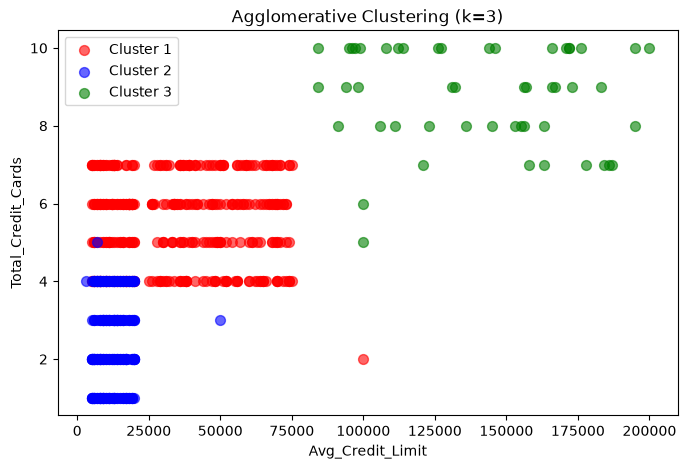

In [15]:
colors = ['red', 'blue', 'green']

plt.figure(figsize=(8, 5))

for c in range(3):
    plt.scatter(
        X.loc[y_hc == c, 'Avg_Credit_Limit'],
        X.loc[y_hc == c, 'Total_Credit_Cards'],
        s=50, c=colors[c], alpha=0.6, label=f'Cluster {c + 1}'
    )

plt.title('Agglomerative Clustering (k=3)')
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.legend()
plt.show()

**Answer (scatterplot):** The three clusters contain 385, 225 and 50 customers. In the plot of `Avg_Credit_Limit` against `Total_Credit_Cards` the small cluster of 50 customers is the high-limit group with many cards, while the other two clusters overlap in this view because they are mainly separated by the bank visits, online visits and calls, which are not shown in a two-dimensional plot.

### Silhouette Score and DBI

In [16]:
sil = silhouette_score(X_scaled, y_hc)
dbi = davies_bouldin_score(X_scaled, y_hc)

print(f'Silhouette Score: {sil}')
print(f'Davies-Bouldin Index: {dbi}')

Silhouette Score: 0.5147639589977819
Davies-Bouldin Index: 0.680959518994733


**Answer (evaluation):** The silhouette score is 0.5148 and the Davies-Bouldin Index is 0.6810. A silhouette score above 0.5 means that the clusters are reasonably well separated, and a DBI below 1 supports this. These values are almost identical to those of K-Means with k=3 in JS07 (0.5157 and 0.6797), so both methods find the same three customer segments.